<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp29.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Experiment 29: VAE/GAN Sample Generation

Task 1: Build and Train a VAE

In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, Model

tf.random.set_seed(42)
np.random.seed(42)

(x, _), _ = tf.keras.datasets.fashion_mnist.load_data()
x = (x[:3000].astype("float32") / 255).reshape(-1, 784)

# Encoder
inp = layers.Input(shape=(784,))
h = layers.Dense(128, activation='relu')(inp)
mu = layers.Dense(2)(h)
logvar = layers.Dense(2)(h)
encoder = Model(inp, [mu, logvar])

# Decoder
z_in = layers.Input(shape=(2,))
h = layers.Dense(128, activation='relu')(z_in)
out = layers.Dense(784, activation='sigmoid')(h)
decoder = Model(z_in, out)

optimizer = tf.keras.optimizers.Adam(0.001)
vae_losses = []

for epoch in range(5):
    total = 0
    for batch in tf.data.Dataset.from_tensor_slices(x).batch(128):
        with tf.GradientTape() as tape:
            m, lv = encoder(batch)
            z = m + tf.exp(0.5 * lv) * tf.random.normal(tf.shape(m))
            recon = decoder(z)

            rec_loss = tf.reduce_mean(
                tf.reduce_sum(
                    tf.keras.backend.binary_crossentropy(batch, recon),
                    axis=1
                )
            )
            kl = -0.5 * tf.reduce_mean(
                tf.reduce_sum(1 + lv - m**2 - tf.exp(lv), axis=1)
            )
            loss = rec_loss + kl

        variables = encoder.trainable_variables + decoder.trainable_variables
        grads = tape.gradient(loss, variables)
        optimizer.apply_gradients(zip(grads, variables))
        total += float(loss)

    vae_losses.append(total)
    print("Epoch", epoch + 1, "Loss:", round(total, 2))


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1 Loss: 11879.14
Epoch 2 Loss: 9419.0
Epoch 3 Loss: 8373.58
Epoch 4 Loss: 7852.54
Epoch 5 Loss: 7547.04


Task 2: Generate Images from the Latent Space

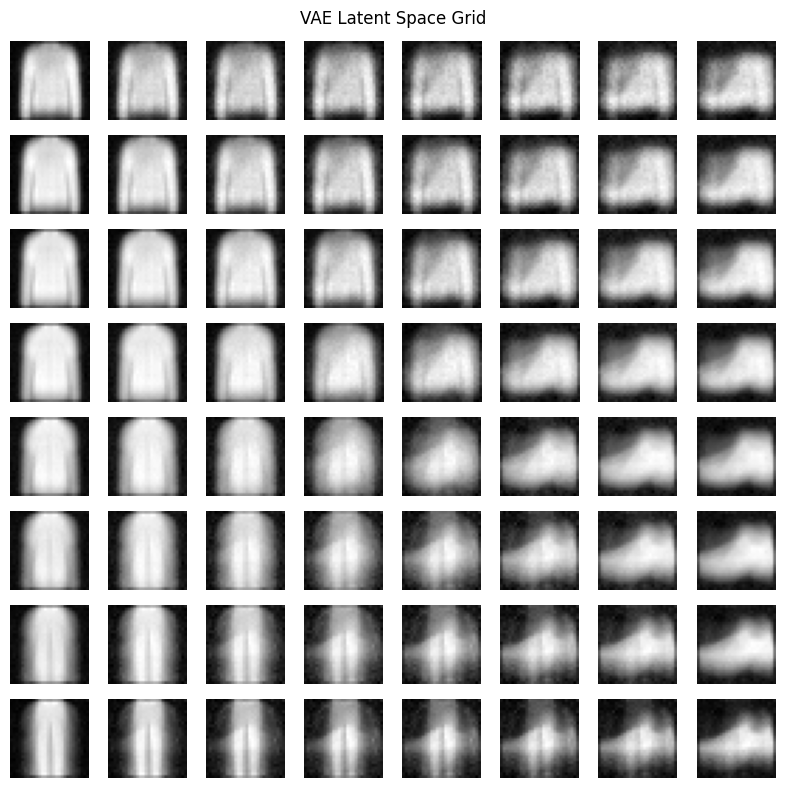

In [2]:

from scipy.stats import norm

grid = 8
points = norm.ppf(np.linspace(0.05, 0.95, grid))

fig, axes = plt.subplots(grid, grid, figsize=(8, 8))

for i, y in enumerate(points[::-1]):
    for j, x_val in enumerate(points):
        z = np.array([[x_val, y]], dtype='float32')
        image = decoder(z, training=False).numpy().reshape(28, 28)
        axes[i, j].imshow(image, cmap='gray')
        axes[i, j].axis('off')

plt.suptitle("VAE Latent Space Grid")
plt.tight_layout()
plt.show()


Task 3: Build a DCGAN Generator and Discriminator

In [3]:

generator = tf.keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(7 * 7 * 128),
    layers.Reshape((7, 7, 128)),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(64, 4, strides=2, padding='same'),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Conv2DTranspose(1, 4, strides=2,
                           padding='same', activation='tanh')
])

discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 4, strides=2, padding='same'),
    layers.LeakyReLU(),
    layers.Conv2D(64, 4, strides=2, padding='same'),
    layers.LeakyReLU(),
    layers.Flatten(),
    layers.Dense(1)
])

print("Generator:", generator.output_shape)
print("Discriminator:", discriminator.output_shape)


Generator: (None, 28, 28, 1)
Discriminator: (None, 1)


Task 4: Train the GAN and Save Generated Images

In [4]:

gan_x = x.reshape(-1, 28, 28, 1) * 2 - 1
dataset = tf.data.Dataset.from_tensor_slices(
    gan_x.astype('float32')
).shuffle(3000).batch(128)

g_opt = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)

g_losses, d_losses = [], []
fixed_noise = tf.random.normal((9, 100))

for epoch in range(5):
    g_total, d_total, batches = 0, 0, 0

    for real in dataset:
        noise = tf.random.normal((tf.shape(real)[0], 100))

        with tf.GradientTape() as gt, tf.GradientTape() as dt:
            fake = generator(noise, training=True)
            real_out = discriminator(real, training=True)
            fake_out = discriminator(fake, training=True)

            g_loss = bce(tf.ones_like(fake_out), fake_out)
            d_loss = (
                bce(tf.ones_like(real_out), real_out) +
                bce(tf.zeros_like(fake_out), fake_out)
            )

        g_grad = gt.gradient(g_loss, generator.trainable_variables)
        d_grad = dt.gradient(d_loss, discriminator.trainable_variables)

        g_opt.apply_gradients(zip(g_grad, generator.trainable_variables))
        d_opt.apply_gradients(zip(d_grad, discriminator.trainable_variables))

        g_total += float(g_loss)
        d_total += float(d_loss)
        batches += 1

    g_losses.append(g_total / batches)
    d_losses.append(d_total / batches)

    samples = generator(fixed_noise, training=False).numpy()
    fig, axes = plt.subplots(3, 3, figsize=(4, 4))

    for ax, img in zip(axes.flat, samples):
        ax.imshow((img.squeeze() + 1) / 2, cmap='gray')
        ax.axis('off')

    plt.tight_layout()
    plt.savefig(f"gan_epoch_{epoch+1}.png")
    plt.close()

    print(f"Epoch {epoch+1}: G={g_losses[-1]:.3f}, D={d_losses[-1]:.3f}")

print("Generated images saved.")


Epoch 1: G=0.594, D=1.259
Epoch 2: G=0.477, D=1.312
Epoch 3: G=0.569, D=1.373
Epoch 4: G=0.656, D=1.367
Epoch 5: G=0.633, D=1.417
Generated images saved.


Task 5: Plot Generator and Discriminator Loss Curves

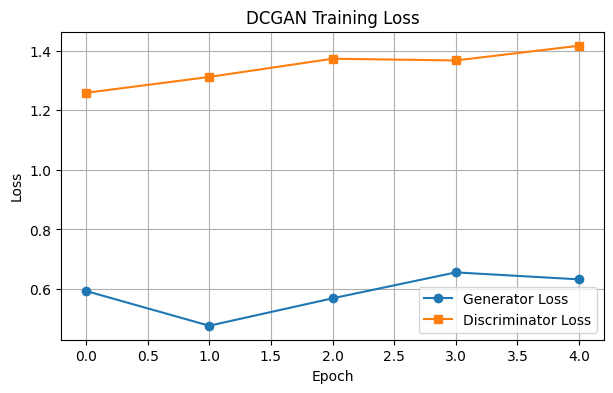

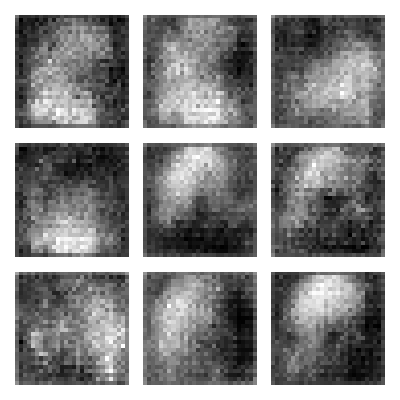

In [5]:

plt.figure(figsize=(7, 4))

plt.plot(g_losses, marker='o', label='Generator Loss')
plt.plot(d_losses, marker='s', label='Discriminator Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.grid(True)
plt.show()

# Display final generated samples
from IPython.display import display, Image
display(Image(filename="gan_epoch_5.png"))
